# Customer Churn Prediction

## Phase 4: Model Training

### Objectives
- Load preprocessed data
- Train Logistic Regression
- Make predictions
- Evaluate classification performance
- Understand classification metrics

# Import Libraries 

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Load Preprocessed Data

In [17]:
data = joblib.load("../data/processed/processed_data.pkl")

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (4929, 50)
Validation: (1057, 50)
Test: (1057, 50)


### Convert target into numeric

In [18]:
y_train = y_train.map({"No": 0, "Yes": 1})
y_val = y_val.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})

print(y_train.value_counts())

Churn
0    3621
1    1308
Name: count, dtype: int64


### Create a Baseline Model

In [19]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)

In [20]:
print("Baseline Accuracy:",
      accuracy_score(y_val, dummy_predictions))

print("Baseline Precision:",
      precision_score(y_val, dummy_predictions, zero_division=0))

print("Baseline Recall:",
      recall_score(y_val, dummy_predictions, zero_division=0))

print("Baseline F1:",
      f1_score(y_val, dummy_predictions, zero_division=0))

Baseline Accuracy: 0.7341532639545885
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


# Train Logistic Regression

In [21]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


# Make Predictions

In [22]:
# Predict class labels
y_val_pred = logistic_model.predict(X_val)

# Predict churn probabilities
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

In [23]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Precision:",
      precision_score(y_val, y_val_pred))

print("Recall:",
      recall_score(y_val, y_val_pred))

print("F1 Score:",
      f1_score(y_val, y_val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_proba))

print("PR-AUC (Average Precision):",
      average_precision_score(y_val, y_val_proba))

Accuracy: 0.7483443708609272
Precision: 0.5177304964539007
Recall: 0.7793594306049823
F1 Score: 0.6221590909090909
ROC-AUC: 0.8328411050372382
PR-AUC (Average Precision): 0.6392715936551433


# Confusion Matrix

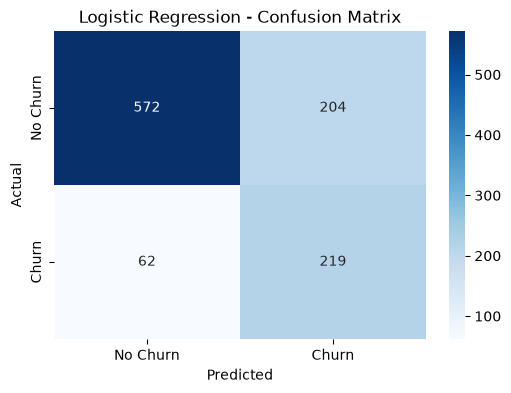

In [24]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

# Classification Report

In [25]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81       776
       Churn       0.52      0.78      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057

